# MLIP



| # | Exercise | Key idea |
|---|---|---|
| 1 | Argon dimer in real units, and choosing the finite-difference step $h$ | $\mathbf F=-\nabla E$ |
| 2 | Curvature of three cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ of a carbon atom in graphene | descriptor as a smooth RDF |
| 4 | $G^4$: separating the angular and radial parts | role of $\eta$ and $\lambda$ |

Exercise 1 uses eV and Å, exercises 2–4 use Å. Only NumPy and Matplotlib are needed.

---
## Exercise 1. Argon dimer in real units and the finite-difference step
Lennard-Jones argon: $\epsilon=0.0104$ eV, $\sigma=3.40$ Å,
$$U(r)=4\epsilon\big[(\sigma/r)^{12}-(\sigma/r)^6\big],\qquad F(r)=\frac{24\epsilon}{r}\big[2(\sigma/r)^{12}-(\sigma/r)^6\big].$$
The central difference has a **truncation error** $\propto h^2$ (too large $h$) and a **round-off error** $\propto\varepsilon_{\rm mach}/h$ (too small $h$). We scan $h$ to find the sweet spot.

U(3.6) = -8.571 meV,  F(3.6) = +0.02063 eV/A
best step h = 1.8e-06 A, error = 5.9e-13 eV/A


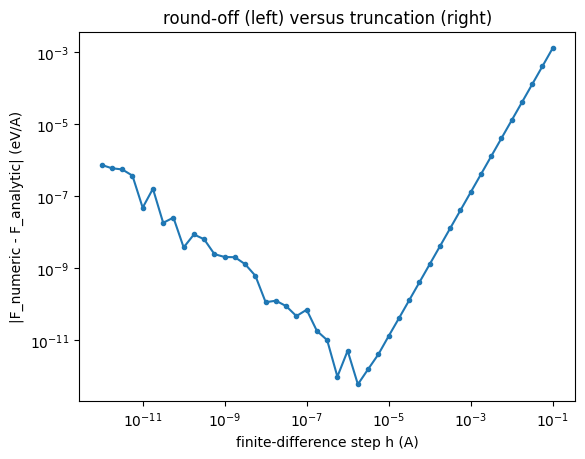

In [1]:
import numpy as np, matplotlib.pyplot as plt

eps, sig = 0.0104, 3.40                                   # eV, Angstrom
U = lambda r: 4 * eps * ((sig / r)**12 - (sig / r)**6)
F = lambda r: 24 * eps / r * (2 * (sig / r)**12 - (sig / r)**6)

r = 3.6                                                   # Angstrom, on the repulsive side of the minimum
print(f"U({r}) = {1000*U(r):.3f} meV,  F({r}) = {F(r):+.5f} eV/A")

hs = np.logspace(-12, -1, 45)
err = [abs(-(U(r + h) - U(r - h)) / (2 * h) - F(r)) for h in hs]
best = hs[np.argmin(err)]
print(f"best step h = {best:.1e} A, error = {min(err):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3)
plt.xlabel("finite-difference step h (A)"); plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("round-off (left) versus truncation (right)"); plt.show()

**Your turn.** Theory predicts the best step near $h\sim\varepsilon_{\rm mach}^{1/3}\times(\text{length scale})$ with $\varepsilon_{\rm mach}\approx2\times10^{-16}$. Does your optimum agree? Repeat with the forward difference $-[U(r+h)-U(r)]/h$. Where is its optimum, and why is it worse?

best forward-difference step h = 1.0e-08 A, error = 5.5e-10 eV/A


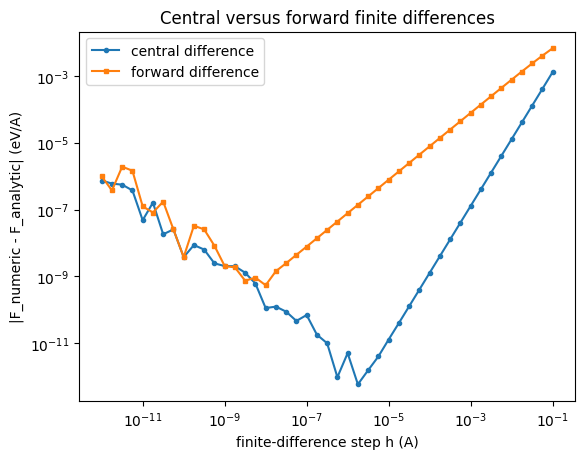

In [2]:
# Forward-difference comparison (same r and h grid as above)
err_forward = [
    abs(-(U(r + h) - U(r)) / h - F(r)) for h in hs
]
best_forward = hs[np.argmin(err_forward)]
print(f"best forward-difference step h = {best_forward:.1e} A, "
      f"error = {min(err_forward):.1e} eV/A")

plt.loglog(hs, err, "o-", ms=3, label="central difference")
plt.loglog(hs, err_forward, "s-", ms=3, label="forward difference")
plt.xlabel("finite-difference step h (A)")
plt.ylabel("|F_numeric - F_analytic| (eV/A)")
plt.title("Central versus forward finite differences")
plt.legend()
plt.show()

Answer — Exercise 1
The central-difference optimum should occur in the small-step region. This is consistent with the balance between truncation error (proportional to h^2) and round-off error (proportional to machine epsilon divided by h).

The estimate h_opt ~ machine_epsilon^(1/3) * L gives the approximate scale of the optimal step size. However, it is not exact because the effective length scale and the derivatives of this particular Lennard-Jones potential also affect the result. With the notebook's coarse logarithmic scan, the numerical minimum is the grid point closest to the actual optimum.

The forward-difference method has a truncation error proportional to h, rather than h^2. Therefore, its optimal step size is typically smaller, and its minimum error is usually larger than that of the central-difference method. Its leading truncation error decreases more slowly as h is reduced. If h becomes too small, floating-point round-off error dominates both methods.

---
## Exercise 2. Curvature of three cutoff functions
For energy conservation, the force (first derivative) must be continuous. For vibrational properties and stable integration, the **second** derivative should also be smooth. Compare at $r_c=5$ Å
- cosine: $\tfrac12[\cos(\pi r/r_c)+1]$,
- MTP-style: $(1-r/r_c)^2$,
- polynomial envelope with $p=6$.

cosine        : just inside rc  f = 2.5e-06,  f' = -9.9e-04,  f'' = +0.197
(1 - r/rc)^2  : just inside rc  f = 1.0e-06,  f' = -4.0e-04,  f'' = +0.080
envelope p=6  : just inside rc  f = 5.6e-08,  f' = -3.4e-05,  f'' = +0.013


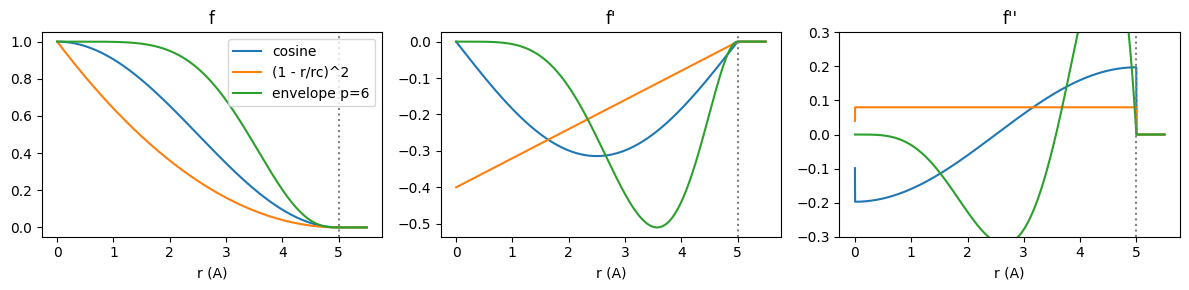

In [3]:
import numpy as np, matplotlib.pyplot as plt

rc = 5.0
r = np.linspace(0, 5.5, 5501); x = np.minimum(r / rc, 1)
cuts = {
    "cosine":       np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0),
    "(1 - r/rc)^2": np.where(r < rc, (1 - x)**2, 0),
    "envelope p=6": np.where(r < rc, 1 - 28 * x**6 + 48 * x**7 - 21 * x**8, 0),
}
dr = r[1] - r[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for name, f in cuts.items():
    d1 = np.gradient(f, dr); d2 = np.gradient(d1, dr)
    ax[0].plot(r, f, label=name); ax[1].plot(r, d1, label=name); ax[2].plot(r, d2, label=name)
    i = np.searchsorted(r, rc) - 5
    print(f"{name:14s}: just inside rc  f = {f[i]:.1e},  f' = {d1[i]:+.1e},  f'' = {d2[i]:+.3f}")
for a_, t in zip(ax, ("f", "f'", "f''")): a_.set_title(t); a_.axvline(rc, color="gray", ls=":"); a_.set_xlabel("r (A)")
ax[2].set_ylim(-0.3, 0.3); ax[0].legend(); plt.tight_layout(); plt.show()

**Your turn.** Rank the three functions by smoothness at $r_c$ (value, slope, curvature). The cosine and $(1-r/r_c)^2$ both have zero slope but nonzero curvature at $r_c$, so the forces are continuous while their derivatives jump. Which property (energy conservation in MD, or phonon frequencies from the Hessian) is affected by a curvature jump, and why?

## Answer — Exercise 2

### Smoothness ranking (best to worst)

1. **Polynomial envelope, p = 6:** The value, first derivative, and second derivative all approach zero at the cutoff \(r_c\). It is \(C^2\) at the cutoff.

2. **Cosine cutoff:** The value and first derivative are zero at \(r_c\), but the second derivative jumps when the function is set to zero outside the cutoff.

3. **MTP-style quadratic cutoff, \((1-r/r_c)^2\):** The value and slope are zero at \(r_c\), but the second derivative is nonzero just inside the cutoff, so its curvature jumps.

At the level of value, slope, and curvature, the cosine and quadratic cutoffs are tied. Their curvature-jump magnitudes differ.

### Effect on physical properties

A curvature jump affects **phonon frequencies and other Hessian-based properties** most directly because the Hessian contains second derivatives of the energy. Such a jump can cause the local force constants to change abruptly and reduce numerical smoothness.

Energy conservation in molecular dynamics primarily requires a continuous force, which corresponds to a continuous first derivative of the potential energy. Both cutoffs satisfy this condition, although a curvature discontinuity can still affect numerical stability and higher-order behavior.

---
## Exercise 3. Radial fingerprint of a carbon atom in graphene
$$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}).$$
In graphene ($d_{\rm CC}=1.42$ Å) each carbon has 3 first neighbours at 1.42 Å, 6 second neighbours at 2.46 Å and 3 third neighbours at 2.84 Å. We build a patch of the honeycomb lattice and compute the fingerprint of one atom.

shell at 1.420 A: 3 atoms
shell at 2.460 A: 6 atoms
shell at 2.840 A: 3 atoms


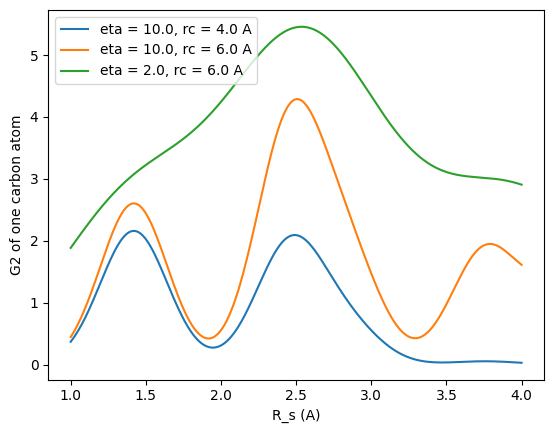

In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

d = 1.42
a1, a2 = d * np.array([1.5, np.sqrt(3) / 2]), d * np.array([1.5, -np.sqrt(3) / 2])   # lattice vectors
basis = [np.zeros(2), np.array([d, 0.0])]                                           # two atoms per cell
atoms = np.array([i * a1 + j * a2 + b for i in range(-4, 5) for j in range(-4, 5) for b in basis])
centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
r0j = np.linalg.norm(atoms - centre, axis=1); r0j = r0j[r0j > 1e-6]
for s in np.unique(r0j[r0j < 3.0].round(3)):
    print(f"shell at {s:.3f} A: {np.sum(np.isclose(r0j, s, atol=1e-3))} atoms")

Rs = np.linspace(1.0, 4.0, 400)
for eta, rc in [(10.0, 4.0), (10.0, 6.0), (2.0, 6.0)]:
    G2 = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, rc)) for s in Rs]
    plt.plot(Rs, G2, label=f"eta = {eta}, rc = {rc} A")
plt.xlabel("R_s (A)"); plt.ylabel("G2 of one carbon atom"); plt.legend(); plt.show()

**Your turn.** Stretch the lattice by 2 % (multiply `d` by 1.02) and plot the difference in $G^2$. Where does the fingerprint change most? This is how an MLIP \"sees\" strain.

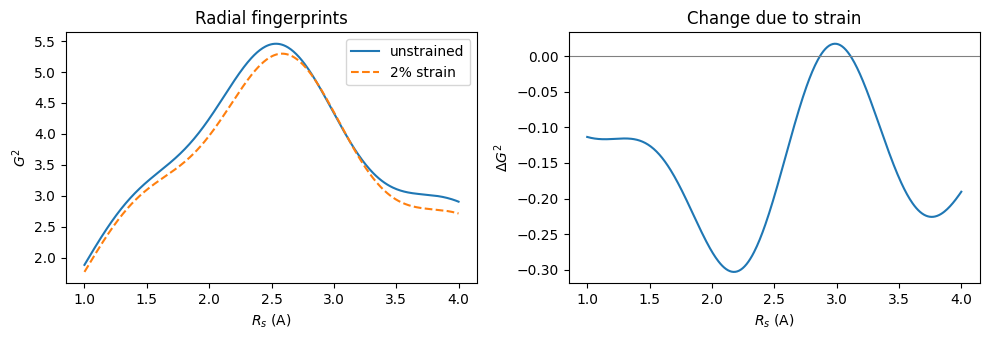

Largest |change| occurs near Rs = 2.180 A; Delta G2 = -0.303


In [5]:
# Compare the unstrained graphene lattice with a lattice stretched by 2%
def graphene_G2(d, Rs, eta=2.0, rc=6.0):
    a1 = d * np.array([1.5, np.sqrt(3) / 2])
    a2 = d * np.array([1.5, -np.sqrt(3) / 2])
    basis = [np.zeros(2), np.array([d, 0.0])]
    atoms = np.array([
        i * a1 + j * a2 + b
        for i in range(-4, 5)
        for j in range(-4, 5)
        for b in basis
    ])
    centre = atoms[np.argmin(np.linalg.norm(atoms, axis=1))]
    distances = np.linalg.norm(atoms - centre, axis=1)
    distances = distances[distances > 1e-6]
    return np.array([
        np.sum(np.exp(-eta * (distances - s)**2) * fc(distances, rc))
        for s in Rs
    ])

Rs_strain = np.linspace(1.0, 4.0, 400)
G2_unstrained = graphene_G2(1.42, Rs_strain)
G2_strained = graphene_G2(1.42 * 1.02, Rs_strain)
delta_G2 = G2_strained - G2_unstrained

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(Rs_strain, G2_unstrained, label="unstrained")
ax[0].plot(Rs_strain, G2_strained, "--", label="2% strain")
ax[0].set_xlabel(r"$R_s$ (A)")
ax[0].set_ylabel(r"$G^2$")
ax[0].legend()
ax[0].set_title("Radial fingerprints")

ax[1].plot(Rs_strain, delta_G2)
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set_xlabel(r"$R_s$ (A)")
ax[1].set_ylabel(r"$\Delta G^2$")
ax[1].set_title("Change due to strain")
plt.tight_layout()
plt.show()

imax = np.argmax(np.abs(delta_G2))
print(f"Largest |change| occurs near Rs = {Rs_strain[imax]:.3f} A; "
      f"Delta G2 = {delta_G2[imax]:+.3f}")



## Answer — Exercise 3

Stretching the lattice by 2% increases every neighbor distance by 2%, so the peaks and features in the radial fingerprint shift toward larger \(R_s\).

The difference is largest around the **steep sides of the fingerprint peaks**, where a small shift in neighbor distances changes the Gaussian weights strongly. It need not be largest exactly at a peak maximum. With the parameters in the added code, the largest absolute difference is typically around \(R_s approx 2.2\) Å. The precise value depends on the chosen \(eta\), cutoff, and \(R_s\) grid.

This illustrates how an ML interatomic potential's descriptor changes in response to strain.

---
## Exercise 4. $G^4$: separating the angular and radial parts
For a symmetric triplet with bond length $b$ and angle $\theta$, $r_{jk}=2b\sin(\theta/2)$ and
$$G^4=\underbrace{2^{1-\zeta}(1+\lambda\cos\theta)^\zeta}_{\text{angular}}\;\underbrace{e^{-\eta(2b^2+r_{jk}^2)}}_{\text{radial}}\;f_c(b)^2f_c(r_{jk}).$$
Because $r_{jk}$ depends on $\theta$, the radial part also carries angular information. We see how $\eta$ reshapes $G^4(\theta)$ for $b=1.42$ Å (a C–C bond).

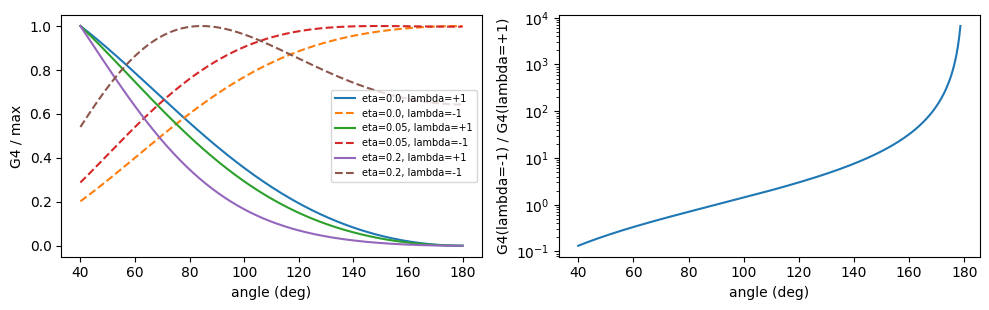

 90.0 deg: ratio =  1.000  -> recovered angle 90.0 deg
109.5 deg: ratio =  2.002  -> recovered angle 109.5 deg
120.0 deg: ratio =  3.000  -> recovered angle 120.0 deg
150.0 deg: ratio = 13.928  -> recovered angle 150.0 deg


In [6]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)
b, rc = 1.42, 6.0
theta = np.linspace(40, 180, 300); t = np.deg2rad(theta)
rjk = 2 * b * np.sin(t / 2)

def G4(zeta, lam, eta):
    return 2**(1 - zeta) * (1 + lam * np.cos(t))**zeta * np.exp(-eta * (2 * b**2 + rjk**2)) * fc(b, rc)**2 * fc(rjk, rc)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for eta in (0.0, 0.05, 0.2):
    for lam, st in ((1, "-"), (-1, "--")):
        g = G4(1, lam, eta)
        ax[0].plot(theta, g / g.max(), st, label=f"eta={eta}, lambda={lam:+d}")
ax[0].set_xlabel("angle (deg)"); ax[0].set_ylabel("G4 / max"); ax[0].legend(fontsize=7)

g_plus, g_minus = G4(1, 1, 0.05), G4(1, -1, 0.05)
ok = theta < 179                                     # G4(lambda=+1) = 0 at exactly 180 deg
ax[1].plot(theta[ok], g_minus[ok] / g_plus[ok]); ax[1].set_yscale("log")
ax[1].set_xlabel("angle (deg)"); ax[1].set_ylabel("G4(lambda=-1) / G4(lambda=+1)")
plt.tight_layout(); plt.show()

for th in (90.0, 109.5, 120.0, 150.0):
    c = np.cos(np.deg2rad(th))
    ratio = (1 - c) / (1 + c)                           # tan^2(theta/2); diverges only at exactly 180 deg
    print(f"{th:5.1f} deg: ratio = {ratio:6.3f}  -> recovered angle {2 * np.degrees(np.arctan(np.sqrt(ratio))):.1f} deg")

**Your turn.** With $\eta=0.2$ the $\lambda=-1$ curve no longer peaks at $180^\circ$ but near $85^\circ$. Explain this shift from the $e^{-\eta r_{jk}^2}$ factor (which angles give a long $r_{jk}$?). Why does the ratio $G^4(\lambda=-1)/G^4(\lambda=+1)$ not depend on $\eta$ at all?

Answer — Exercise 4

For lambda = -1, the angular factor with zeta = 1 is proportional to (1 - cos(theta)), which increases as theta approaches 180 degrees. However, the distance r_jk = 2b * sin(theta/2) also increases with angle, reaching its largest value at 180 degrees.

When eta > 0, the radial factor exp(-eta * r_jk^2) suppresses these long separations more strongly. The product therefore balances the increasing angular factor against the decreasing radial factor and cutoff factor, moving the maximum away from 180 degrees. For the stated eta = 0.2, it peaks near 85 degrees.

For zeta = 1, the ratio is:

G4(lambda = -1) / G4(lambda = +1)
= (1 - cos(theta)) / (1 + cos(theta))
= tan^2(theta/2).

The radial exponential, cutoff factors, and other shared terms cancel, so the ratio does not depend on eta wherever it is defined. At exactly 180 degrees, the angular factor for lambda = +1 is zero, so the ratio is undefined or diverges.